# Лабораторная работа №3. Арифметические вычисления

**Монгуш Темир Мергенович · ИУ5-35Б · вариант 11**

Цель: изучить передачу аргументов командной строки, преобразование строк в числа,
целочисленные вычисления и вывод результатов в Linux x86-64.

**Задания:**
1. На ассемблере вывести ASCII-код переданного символа.
2. На ассемблере вычислить выражение варианта: `((((c/b)+a)/c)+a)`.
3. Реализовать то же выражение на C и сравнить результаты.

**Новая версия:** обе ASM-программы самостоятельные, нужные процедуры включены
непосредственно в каждый исходник. Дополнительные include-файлы не требуются.

[Условие](https://github.com/junaart/System_programming/blob/master/Lab_3/Lab_3.ipynb)
· [Лекция 3](https://github.com/junaart/System_programming/blob/master/Lection_3/Lection_3.ipynb)

**Colab:** выбрать Python 3 / CPU, подключиться и выполнить все ячейки сверху вниз.
Исходники создаются в папке Lab_3, затем собираются и проверяются.
В VS Code с Linux-ядром запускать из корня проекта.

Сохранённые результаты получены реальным выполнением в Ubuntu через WSL 2.
В Colab эти же проверки можно воспроизвести; версии инструментов выводятся ниже.


## Подготовка

In [1]:
%%bash
set -e
if ! dpkg -s fasm binutils gcc file fonts-dejavu-core >/dev/null 2>&1; then
    SUDO=()
    if [ "$(id -u)" -ne 0 ]; then SUDO=(sudo); fi
    "${SUDO[@]}" apt-get update -qq
    "${SUDO[@]}" env DEBIAN_FRONTEND=noninteractive apt-get install -y -qq fasm binutils gcc file fonts-dejavu-core
fi
mkdir -p Lab_3
uname -sm
. /etc/os-release
printf "%s\n" "$PRETTY_NAME"
fasm | head -n 1
gcc --version | head -n 1

Linux x86_64
Ubuntu 26.04.1 LTS
flat assembler  version 1.73.34
gcc (Ubuntu 15.2.0-16ubuntu1) 15.2.0


## Вариант

In [2]:
import random as rd
Variant = 11
rd.seed(Variant)
operations = ['-','+','*','/']
operands = ['a','b','c']
count = rd.randint(3,5)
expression = operands[rd.randint(0,2)]
for _ in range(count):
    operation = operations[rd.randint(0,3)]
    operand = operands[rd.randint(0,2)]
    expression = '(' + expression + operation + operand + ')'
print(expression)
assert expression == '((((c/b)+a)/c)+a)'

((((c/b)+a)/c)+a)


## Самостоятельные программы

В каждой программе нужные процедуры находятся в том же `.asm`-файле. `ascii.asm` содержит вывод числа и обработку ошибок; `expression.asm` также содержит преобразование аргументов в числа. Дополнительные include-файлы не нужны.


## 1. ASCII-код символа из командной строки

Один аргумент должен содержать один ASCII-байт. Проверяются число аргументов, длина строки и диапазон 0–127. `movzx` получает числовой код; `print_int` превращает его в десятичную строку.

In [3]:
%%writefile Lab_3/ascii.asm
format ELF64
public _start
section '.text' executable
_start:
    cmp qword [rsp], 2
    jne error
    mov rsi, [rsp+16]
    cmp byte [rsi], 0
    je error
    cmp byte [rsi+1], 0
    jne error
    movzx eax, byte [rsi]
    cmp eax, 127
    ja error
    call print_int
    jmp exit

; print_int: вывести int64 из rax и перевод строки через write.
print_int:
    xor r10d, r10d
    test rax, rax
    jns .convert
    inc r10d
    neg rax
.convert:
    mov r8d, 10
    mov rsi, number_buffer+31
    mov byte [rsi], 10
    mov edx, 1
.loop:
    push rdx
    xor edx, edx
    div r8
    add dl, '0'
    dec rsi
    mov [rsi], dl
    pop rdx
    inc rdx
    test rax, rax
    jnz .loop
    test r10d, r10d
    jz .write
    dec rsi
    mov byte [rsi], '-'
    inc rdx
.write:
    mov edi, 1
    mov eax, 1
    syscall
    ret

exit:
    mov eax, 60
    xor edi, edi
    syscall
error:
    mov eax, 1
    mov edi, 2
    mov rsi, error_message
    mov edx, error_length
    syscall
    mov eax, 60
    mov edi, 1
    syscall

section '.data' writable
error_message db 'Invalid input or I/O error',10
error_length = $-error_message
section '.bss' writable
number_buffer rb 32


Writing Lab_3/ascii.asm


In [4]:
%%bash
set -e
cd Lab_3
fasm ascii.asm ascii.o >/dev/null
ld ascii.o -o ascii
for ch in A z 0 '!'; do
    echo "$ ./ascii '$ch'"
    ./ascii "$ch"
done

$ ./ascii 'A'
65
$ ./ascii 'z'
122
$ ./ascii '0'
48
$ ./ascii '!'
33


## 2. Вычисление выражения на ассемблере

Числа передаются в порядке **a b c**. В r12, r13, r14 сохраняются a, b, c.
В rax хранится результат, в rbx — делитель. `cqo` готовит rdx:rax к знаковому
делению `idiv`; дробная часть отбрасывается к нулю.

Для a=5, b=2, c=6: **6/2=3 → 3+5=8 → 8/6=1 → 1+5=6**.
Значения 5, 2, 6 — пример, а вариант задаёт формулу.
Проверяются деление на ноль, INT64_MIN / -1 и знаковое переполнение сложения.


In [5]:
%%writefile Lab_3/expression.asm
; Вариант 11: ((((c/b)+a)/c)+a). Целочисленное деление.
format ELF64
public _start
section '.text' executable
_start:
    cmp qword [rsp], 4
    jne error
    mov rsi, [rsp+16]
    call parse_int
    mov r12, rax                     ; a
    mov rsi, [rsp+24]
    call parse_int
    mov r13, rax                     ; b
    mov rsi, [rsp+32]
    call parse_int
    mov r14, rax                     ; c
    test r13, r13
    jz error
    test r14, r14
    jz error
    mov rax, r14
    mov rbx, r13
    call divide
    add rax, r12
    jo error
    mov rbx, r14
    call divide
    add rax, r12
    jo error
    call print_int
    jmp exit
divide:
    mov rdx, 8000000000000000h
    cmp rax, rdx
    jne .ok
    cmp rbx, -1
    je error
.ok:
    cqo
    idiv rbx
    ret

; parse_uint: rsi -> строка, rax <- число; строгая проверка uint64.
parse_uint:
    xor eax, eax
    mov r8d, 10
    cmp byte [rsi], 0
    je error
.loop:
    movzx r9d, byte [rsi]
    test r9b, r9b
    jz .done
    sub r9d, '0'
    cmp r9d, 9
    ja error
    mul r8
    test rdx, rdx
    jnz error
    add rax, r9
    jc error
    inc rsi
    jmp .loop
.done:
    ret

; parse_int: rsi -> строка, rax <- int64.
parse_int:
    xor r10d, r10d
    cmp byte [rsi], '-'
    jne .positive
    inc rsi
    inc r10d
    jmp .convert
.positive:
    cmp byte [rsi], '+'
    jne .convert
    inc rsi
.convert:
    call parse_uint
    mov r9, 7FFFFFFFFFFFFFFFh
    add r9, r10
    cmp rax, r9
    ja error
    test r10d, r10d
    jz .done
    neg rax
.done:
    ret

; print_int: вывести int64 из rax и перевод строки через write.
print_int:
    xor r10d, r10d
    test rax, rax
    jns .convert
    inc r10d
    neg rax
.convert:
    mov r8d, 10
    mov rsi, number_buffer+31
    mov byte [rsi], 10
    mov edx, 1
.loop:
    push rdx
    xor edx, edx
    div r8
    add dl, '0'
    dec rsi
    mov [rsi], dl
    pop rdx
    inc rdx
    test rax, rax
    jnz .loop
    test r10d, r10d
    jz .write
    dec rsi
    mov byte [rsi], '-'
    inc rdx
.write:
    mov edi, 1
    mov eax, 1
    syscall
    ret

exit:
    mov eax, 60
    xor edi, edi
    syscall
error:
    mov eax, 1
    mov edi, 2
    mov rsi, error_message
    mov edx, error_length
    syscall
    mov eax, 60
    mov edi, 1
    syscall

section '.data' writable
error_message db 'Invalid input or I/O error',10
error_length = $-error_message
section '.bss' writable
number_buffer rb 32


Writing Lab_3/expression.asm


## 3. Программа на C

`argc` и `argv` — количество аргументов и указатели на строки. `strtoll` преобразует строку в число; `errno` и `end` проверяют диапазон и лишние символы. `int64_t` — знаковый 64-битный тип; `__builtin_add_overflow` проверяет сложение; `PRId64` задаёт формат печати.

In [6]:
%%writefile Lab_3/expression.c
#include <stdio.h>
#include <stdlib.h>
#include <stdint.h>
#include <errno.h>
#include <inttypes.h>
static int64_t number(const char *s) {
    char *end;
    errno = 0;
    int64_t x = strtoll(s, &end, 10);
    if (errno || !*s || *end) exit(1);
    return x;
}
int main(int argc, char **argv) {
    if (argc != 4) return 1;
    int64_t a = number(argv[1]), b = number(argv[2]), c = number(argv[3]);
    if (!b || !c || (c == INT64_MIN && b == -1)) return 1;
    int64_t x;
    if (__builtin_add_overflow(c / b, a, &x)) return 1;
    if (x == INT64_MIN && c == -1) return 1;
    if (__builtin_add_overflow(x / c, a, &x)) return 1;
    printf("%" PRId64 "\n", x);
    return 0;
}

Writing Lab_3/expression.c


In [7]:
%%bash
set -e
cd Lab_3
fasm expression.asm expression.o >/dev/null
ld expression.o -o expression
gcc -Wall -Wextra -O0 expression.c -o expression_c

In [8]:
from pathlib import Path
import subprocess
p = Path('Lab_3').resolve()
def trunc(x,y):
    return abs(x)//abs(y) * (-1 if (x<0) != (y<0) else 1)
print('a       b       c       ASM     C       проверка')
for a,b,c in [(2,3,12),(5,2,6),(-5,2,6),(5,-2,6),(5,2,-6),(0,7,9),(100,3,11)]:
    expected = trunc(trunc(c,b)+a,c)+a
    args = list(map(str,(a,b,c)))
    asm = subprocess.check_output([str(p/'expression'),*args],text=True).strip()
    cpp = subprocess.check_output([str(p/'expression_c'),*args],text=True).strip()
    assert asm == cpp == str(expected)
    print(f'{a:<8}{b:<8}{c:<8}{asm:<8}{cpp:<8}OK')
for args in [('1','0','2'),('1','2','0'),('x','1','2')]:
    r = subprocess.run([str(p/'expression'),*args],capture_output=True,text=True)
    assert r.returncode != 0
    print('Ошибка ввода', ' '.join(args), '->', r.stderr.strip())

a       b       c       ASM     C       проверка
2       3       12      2       2       OK
5       2       6       6       6       OK
-5      2       6       -5      -5      OK
5       -2      6       5       5       OK
5       2       -6      5       5       OK
0       7       9       0       0       OK
100     3       11      109     109     OK
Ошибка ввода 1 0 2 -> Invalid input or I/O error
Ошибка ввода 1 2 0 -> Invalid input or I/O error
Ошибка ввода x 1 2 -> Invalid input or I/O error


## Дополнительные проверки и изображения вывода

Ниже выполняются 100 воспроизводимых наборов для сравнения ASM, C и независимого
целочисленного расчёта, проверки ошибочного ввода и крайних значений int64.
Изображения формируются из фактического stdout/stderr выполненных программ.


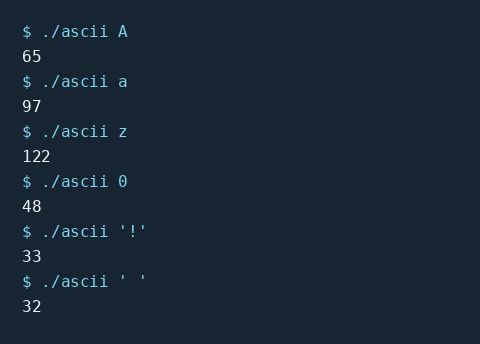

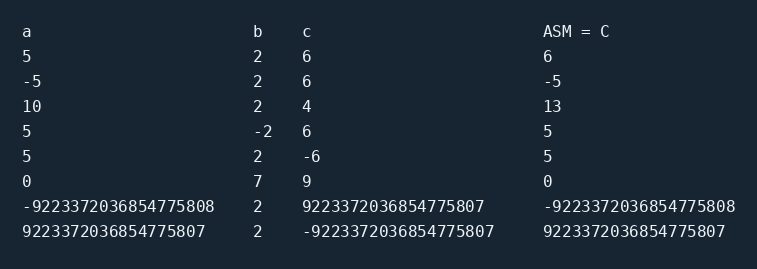

100 дополнительных наборов: ASM = C = независимый расчёт — OK


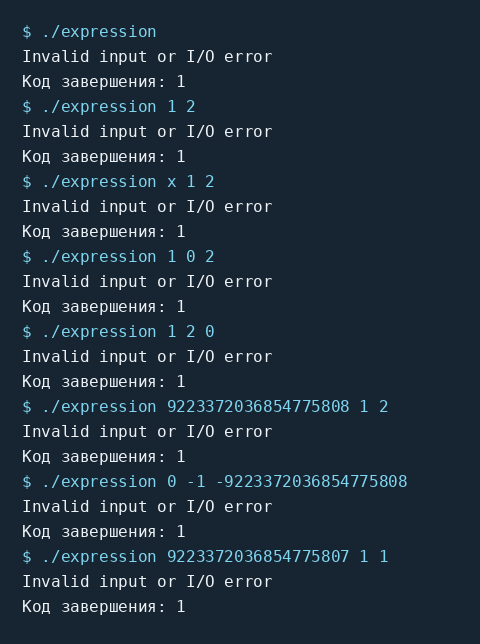

ASCII: 6 верных и 5 ошибочных наборов — OK
Выражение: примеры, границы int64 и 8 ошибочных наборов — OK
Все проверки пройдены.


In [9]:
from pathlib import Path
import importlib.util
import random
import shlex
import subprocess
import sys
import textwrap

if importlib.util.find_spec('PIL') is None:
    subprocess.check_call([sys.executable,'-m','pip','install','-q','Pillow'])
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

lab = Path('Lab_3').resolve()
frames = lab/'report_frames'
frames.mkdir(exist_ok=True)

def execute(name,*args):
    return subprocess.run([str(lab/name),*map(str,args)],text=True,capture_output=True,timeout=5)

def show_terminal(lines,name):
    lines=[part for line in lines for part in (textwrap.wrap(line,width=96,replace_whitespace=False,drop_whitespace=False) or [''])]
    font=ImageFont.truetype('/usr/share/fonts/truetype/dejavu/DejaVuSansMono.ttf',16)
    width=max(480,int(max(font.getlength(line) for line in lines))+44)
    image=Image.new('RGB',(width,len(lines)*25+44),'#172431')
    draw=ImageDraw.Draw(image)
    for index,line in enumerate(lines):
        draw.text((22,22+index*25),line,font=font,fill='#7ed5ef' if line.startswith('$') else '#edf2f6')
    image.save(frames/name)
    display(image)

ascii_lines=[]
for character in ['A','a','z','0','!',' ']:
    process=execute('ascii',character)
    assert process.returncode==0 and process.stdout==f'{ord(character)}\n'
    ascii_lines.extend(['$ ./ascii '+shlex.quote(character),process.stdout.rstrip()])
show_terminal(ascii_lines,'ascii.png')

examples=[(5,2,6),(-5,2,6),(10,2,4),(5,-2,6),(5,2,-6),(0,7,9),
          (-(2**63),2,2**63-1),(2**63-1,2,-(2**63-1))]
comparison=['a                       b    c                        ASM = C']
for a,b,c in examples:
    asm=execute('expression',a,b,c)
    cpp=execute('expression_c',a,b,c)
    expected=trunc(trunc(c,b)+a,c)+a
    assert asm.returncode==cpp.returncode==0
    assert asm.stdout==cpp.stdout==str(expected)+'\n'
    comparison.append(f'{a:<24}{b:<5}{c:<25}{expected}')
show_terminal(comparison,'comparison.png')

rng=random.Random(11)
for _ in range(100):
    a,b,c=[rng.randint(-10000,10000) for _ in range(3)]
    b=b or 1
    c=c or 1
    asm=execute('expression',a,b,c)
    cpp=execute('expression_c',a,b,c)
    assert asm.returncode==cpp.returncode==0
    assert asm.stdout==cpp.stdout==str(trunc(trunc(c,b)+a,c)+a)+'\n'
print('100 дополнительных наборов: ASM = C = независимый расчёт — OK')

for args in [(),('',),('AB',),('я',),('A','B')]:
    process=execute('ascii',*args)
    assert process.returncode==1 and process.stderr

invalid=[(),('1','2'),('x','1','2'),('1','0','2'),('1','2','0'),
         ('9223372036854775808','1','2'),('0','-1','-9223372036854775808'),
         ('9223372036854775807','1','1')]
errors=[]
for args in invalid:
    asm=execute('expression',*args)
    cpp=execute('expression_c',*args)
    assert asm.returncode==cpp.returncode==1
    assert asm.stdout=='' and asm.stderr and cpp.stdout==''
    errors.extend(['$ ./expression '+' '.join(args),asm.stderr.rstrip(),'Код завершения: 1'])
show_terminal(errors,'errors.png')
print('ASCII: 6 верных и 5 ошибочных наборов — OK')
print('Выражение: примеры, границы int64 и 8 ошибочных наборов — OK')
print('Все проверки пройдены.')


## Что означают процедуры и регистры

| Элемент | Назначение |
|---|---|
| `_start` | Начало выполнения ассемблерной программы |
| `[rsp]`, `[rsp+16]` | Количество аргументов и адрес первого аргумента при входе |
| `parse_uint` | Накопление числа: предыдущее значение × 10 + цифра |
| `parse_int` | Обработка знака и проверка диапазона int64 |
| `print_int` | Преобразование числа в строку и вывод |
| `call`, `ret` | Вызов процедуры с сохранением адреса возврата и возврат |
| `jo`, `jc` | Знаковое переполнение и перенос |
| `syscall` | Обращение к Linux: write — номер 1, exit — номер 60 |

Для write: rdi — дескриптор (1 — stdout, 2 — stderr), rsi — адрес, rdx — длина.
Для exit: rdi — код завершения (0 — успех, 1 — ошибка).
Результат формулы и код завершения процесса — разные значения.

## Вывод

Разработаны две самостоятельные программы на FASM и аналог вычисления на C.
Проверен вывод ASCII-кодов; результаты выражения на ASM и C совпали с независимым
расчётом на демонстрационных, граничных и 100 дополнительных наборах.
Проверены неверный ввод, деление на ноль и переполнение. Исходники, результаты
реальных запусков и изображения вывода включены в отчёт.
